In [ ]:
import pathlib

import marimo as mo
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
from scipy import optimize as sp_optimize
from scipy import stats as scipy_stats
import seaborn as sns
from teeplot import teeplot as tp
from watermark import watermark

from pylib.theory._calc_denovo_fixprob import calc_denovo_fixprob
from pylib.theory._calc_selection_from_num_sweeps import (
    calc_selection_from_num_sweeps,
)
from pylib.theory._calc_sweep_lag import calc_sweep_lag

In [ ]:
mo.md(
    f"""
```Text
{watermark(
    current_date=True,
    iso8601=True,
    machine=True,
    updated=True,
    python=True,
    iversions=True,
    globals_=globals(),
)}
```
"""
)

```Text
Last updated: 2026-11-26T02:18:56.718303+00:00

Python implementation: CPython
Python version       : 3.10.22
IPython version      : 7.31.1

Compiler    : GCC 13.3.0
OS          : Linux
Release     : 7.0.0-1017-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 4
Architecture: 64bit

scipy     : 1.14.1
matplotlib: 3.9.2
marimo    : 0.23.2
numpy     : 2.1.2
seaborn   : 0.13.2
pandas    : 2.2.3
teeplot   : 1.2.0

```

In [ ]:
teeplot_subdir = pathlib.Path(__file__).stem
teeplot_subdir

'callens2023-hypermutator-emergence'

# Applying the *de novo* mutator model to Callens et al. (2023)

[Callens et al. (2023)](https://doi.org/10.1093/evlett/qrad019) evolved 95 *E. coli* populations for ~1,000 generations under antibiotic stress, osmotic stress, or no stress, and tracked emergence of hypermutators.
Hypermutators emerged more often under osmotic stress, where more loci contribute to adaptation (43, versus 23 under antibiotic stress).

Here we ask what the well-mixed *de novo* model (`calc_denovo_fixprob`) predicts for how many populations hypermutators take over by the end of that experiment.

## Approach

The model's parameters were chosen for the simulations in this repository, not for this experiment, so we set what we can from the experiment itself.

- **Population size** $N$: bottleneck size (10 µL of a 1 mL culture) from optical density, times generations per transfer, times $\ln 2$.
- **Duration**: 148 daily transfers at $\log_2 100 \approx 6.64$ generations each.
- **Adaptive potential** $K$: number of loci inferred to contribute to adaptation (Callens et al. Figure 2D). None is reported for the control, so it is treated as not limiting.
- **Model clock** $s$: the model's selection strength is set so that nonmutators complete as many selective sweeps as the median number of mutations observed to fix in populations that stayed nonmutator (`calc_selection_from_num_sweeps`).
- **Detection lag**: the model counts a hypermutator lineage from the generation it takes the lead. The experiment sees it only once it is common, so the model is evaluated at the experiment's duration less the time for a leading lineage to reach 5% ("emerged") or 90% ("fixed") (`calc_sweep_lag`).

That leaves the supply rate of hypermutators $\mu$, which the experiment does not measure.
We fit it by maximum likelihood, as one rate shared by all treatments and as one rate per treatment.

Rates of beneficial and deleterious mutation and the 100-fold mutator strength are not constrained by these data.
We report how conclusions change under alternative choices, below.

## Prep Data

Tables are derived from the public-domain Dryad deposit, <https://doi.org/10.5061/dryad.hqbzkh1mr>; see `data/callens2023/README.md`.

In [ ]:
data_dir = pathlib.Path(__file__).parent.parent / "data" / "callens2023"
df_populations = pd.read_csv(data_dir / "populations.csv")
df_is10 = pd.read_csv(data_dir / "is10_pcr.csv")
df_od = pd.read_csv(data_dir / "optical_density.csv")

In [ ]:
df_populations

,population,stress,stress level,num mutations,num fixed mutations,num fixed mutations excluding IS,num IS10 insertions,mutator allele frequency,mutator allele genes
0,A40.1,antibiotic,40%,21,13,9,6,0.0,NaN
1,A40.10,antibiotic,40%,30,3,3,2,0.0,NaN
2,A40.11,antibiotic,40%,17,1,1,7,0.0,NaN
3,A40.12,antibiotic,40%,18,4,3,7,0.0,NaN
4,A40.2,antibiotic,40%,32,0,0,6,0.0,NaN
...,...,...,...,...,...,...,...,...,...
87,O60.5,osmotic,60%,82,8,5,65,0.0,NaN
88,O60.6,osmotic,60%,43,7,7,22,0.0,NaN
89,O60.7,osmotic,60%,33,17,8,21,0.0,NaN
90,O60.8,osmotic,60%,325,79,75,17,1.0,mutH


In [ ]:
df_is10[df_is10["first detected transfer"].notna()]

,population,stress,stress level,gene,num assays,first detected transfer,first fixed transfer,final transfer,final status
24,A3.1,antibiotic,60%,mutS,15,88.5,NaN,137.9,WT
36,S1.1,osmotic,20%,mutS,14,52.0,72.5,148.0,MutS IS
37,S1.2,osmotic,20%,mutS,16,99.5,NaN,148.0,WT + MutS IS
40,S1.5,osmotic,20%,mutS,21,40.0,72.5,148.0,MutS IS
42,S1.7,osmotic,20%,mutS,15,117.5,NaN,148.0,WT + MutS IS
...,...,...,...,...,...,...,...,...,...
58,S2.11,osmotic,40%,mutS,10,72.5,137.9,148.0,MutS IS
60,S3.2,osmotic,60%,mutS,12,23.0,72.5,137.9,MutS IS
62,S3.4,osmotic,60%,mutS,10,72.5,137.9,148.0,MutS IS
99,A1.5,antibiotic,20%,mutL,16,119.0,NaN,148.0,WT + MutL IS


In [ ]:
df_od

,stress,stress level,OD600 mean,OD600 std,OD600 count
0,antibiotic,20%,1.0527,0.1478,576
1,antibiotic,40%,0.9737,0.1822,576
2,antibiotic,60%,0.8461,0.2490,576
3,control,NaN,1.2401,0.1198,1152
4,osmotic,20%,0.8633,0.2104,576
5,osmotic,40%,0.7590,0.2630,576
6,osmotic,60%,0.7386,0.2495,558


## Observed Outcomes

A population is counted as having a hypermutator "emerged" if a non-synonymous, indel, or insertion sequence mutation in a known mutator gene was detected at generation 1,000 (frequency of at least 0.05), and "fixed" if it reached frequency 0.9.

In [ ]:
stresses = ["control", "antibiotic", "osmotic"]
outcomes = ["emerged", "fixed"]
df_populations["emerged"] = df_populations["mutator allele frequency"] > 0
df_populations["fixed"] = df_populations["mutator allele frequency"] >= 0.9
_nonmutators = df_populations[~df_populations["emerged"]].groupby("stress")
df_observed = (
    df_populations.groupby("stress")
    .agg(
        **{
            "num populations": ("population", "size"),
            "num emerged": ("emerged", "sum"),
            "num fixed": ("fixed", "sum"),
        },
    )
    .assign(
        **{
            # among populations that stayed nonmutator ...
            "num sweeps": _nonmutators["num fixed mutations"].median(),
            "num sweeps excluding IS": _nonmutators[
                "num fixed mutations excluding IS"
            ].median(),
            "num IS10 insertions": _nonmutators[
                "num IS10 insertions"
            ].median(),
        },
    )
    .loc[stresses]
    .reset_index()
)
for _outcome in outcomes:
    _cis = [
        scipy_stats.binomtest(int(k), int(n)).proportion_ci(
            method="wilson"
        )
        for k, n in zip(
            df_observed[f"num {_outcome}"], df_observed["num populations"]
        )
    ]
    df_observed[f"fraction {_outcome}"] = (
        df_observed[f"num {_outcome}"] / df_observed["num populations"]
    )
    df_observed[f"fraction {_outcome} lo"] = [ci.low for ci in _cis]
    df_observed[f"fraction {_outcome} hi"] = [ci.high for ci in _cis]
df_observed

,stress,num populations,num emerged,num fixed,num sweeps,num sweeps excluding IS,num IS10 insertions,fraction emerged,fraction emerged lo,fraction emerged hi,fraction fixed,fraction fixed lo,fraction fixed hi
0,control,24,2,2,4.0,2.0,6.5,0.083333,0.023159,0.258488,0.083333,0.023159,0.258488
1,antibiotic,35,6,3,4.0,3.0,5.0,0.171429,0.081026,0.326823,0.085714,0.029582,0.223793
2,osmotic,33,15,9,7.0,4.5,21.0,0.454545,0.298429,0.620141,0.272727,0.150674,0.442176


## Model Inputs and Fit

Because hypermutators arrive independently, the model's probability is exactly $1 - e^{-\mu c}$, where $c$ collects everything except the supply rate $\mu$.
We compute $c$ per treatment and outcome, then fit $\mu$ to the observed counts.

Scenarios differ in mutation rates and in how sweeps are counted.

- *baseline*: this repository's default mutation rates ($U_b = 10^{-6}$, $U_d = 10^{-4}$); sweeps counted as all fixed mutations.
- *sweeps excluding IS*: as baseline, but insertion sequence mutations are not counted as sweeps. IS10 is about three times more active under osmotic stress, which could inflate the osmotic sweep count.
- *E. coli rates*: literature estimates for *E. coli*, $U_b = 10^{-5}$ (Perfeito et al. 2007) and $U_d = 2 \times 10^{-4}$ (Kibota & Lynch 1996); sweeps counted as all fixed mutations.

In [ ]:
n_gen = int(round(148 * np.log2(100)))
cells_per_ml_per_od = 8e8  # typical for E. coli in rich medium
transfer_volume_ml = 0.01
mutator_strength = 100.0
detection_frequencies = {"emerged": 0.05, "fixed": 0.9}
scenarios = {
    "baseline": {"Ub": 1e-6, "Ud": 1e-4, "sweeps": "num sweeps"},
    "sweeps excluding IS": {
        "Ub": 1e-6,
        "Ud": 1e-4,
        "sweeps": "num sweeps excluding IS",
    },
    "E. coli rates": {"Ub": 1e-5, "Ud": 2e-4, "sweeps": "num sweeps"},
}

_od = (
    df_od.assign(
        weighted=df_od["OD600 mean"] * df_od["OD600 count"],
    )
    .groupby("stress")[["weighted", "OD600 count"]]
    .sum()
)
_records = []
for _scenario, _params in scenarios.items():
    for __, _row in df_observed.iterrows():
        _stress = _row["stress"]
        _N = (
            _od.loc[_stress, "weighted"]
            / _od.loc[_stress, "OD600 count"]
            * cells_per_ml_per_od
            * transfer_volume_ml
            * np.log2(100)
            * np.log(2)
        )
        # loci contributing to adaptation, per Callens et al. Figure 2D;
        # not reported for control, so taken to be not limiting
        _K = {"antibiotic": 23, "osmotic": 43}.get(_stress, 60)
        _s = calc_selection_from_num_sweeps(
            _N,
            n_gen,
            _row[_params["sweeps"]],
            _params["Ub"],
            _params["Ud"],
        )
        for _outcome in outcomes:
            _lag = calc_sweep_lag(
                _N,
                detection_frequencies[_outcome],
                _s,
                _params["Ud"],
                mutator_strength,
            )
            _n_gen = n_gen - _lag
            _p = (
                calc_denovo_fixprob(
                    _N,
                    _K,
                    s=_s,
                    Ub=_params["Ub"],
                    Ud=_params["Ud"],
                    M=mutator_strength,
                    mu=1e-8,
                    n_gen=int(_n_gen),
                )
                if _n_gen >= 1
                else 0.0
            )
            _records.append(
                {
                    "scenario": _scenario,
                    "stress": _stress,
                    "outcome": _outcome,
                    "population size": _N,
                    "available beneficial mutations": _K,
                    "num sweeps": _row[_params["sweeps"]],
                    "selection strength": _s,
                    "mutator net advantage": _s
                    - mutator_strength * _params["Ud"],
                    "detection lag": _lag,
                    "supply coefficient": -np.log1p(-_p) / 1e-8,
                    "num populations": _row["num populations"],
                    "num observed": _row[f"num {_outcome}"],
                },
            )
df_inputs = pd.DataFrame(_records)
df_inputs

,scenario,stress,outcome,population size,available beneficial mutations,num sweeps,selection strength,mutator net advantage,detection lag,supply coefficient,num populations,num observed
0,baseline,control,emerged,4.568697e+07,60,4.0,0.043809,0.033809,353.273485,1.394028e+06,24,2
1,baseline,control,fixed,4.568697e+07,60,4.0,0.043809,0.033809,505.355145,5.888280e+05,24,2
2,baseline,antibiotic,emerged,3.527560e+07,23,4.0,0.044027,0.034027,343.589034,1.195813e+06,35,6
3,baseline,antibiotic,fixed,3.527560e+07,23,4.0,0.044027,0.034027,494.695612,5.355646e+05,35,3
4,baseline,osmotic,emerged,2.901168e+07,43,7.0,0.077966,0.067966,178.702365,4.279276e+06,33,15
...,...,...,...,...,...,...,...,...,...,...,...,...
13,E. coli rates,control,fixed,4.568697e+07,60,4.0,0.030373,0.010373,1533.385778,0.000000e+00,24,2
14,E. coli rates,antibiotic,emerged,3.527560e+07,23,4.0,0.030485,0.010485,1003.039796,0.000000e+00,35,6
15,E. coli rates,antibiotic,fixed,3.527560e+07,23,4.0,0.030485,0.010485,1493.424323,0.000000e+00,35,3
16,E. coli rates,osmotic,emerged,2.901168e+07,43,7.0,0.054281,0.034281,335.142721,8.020107e+06,33,15


In [ ]:
def calc_neg_log_likelihood(log10_mu: float, group: pd.DataFrame) -> float:
    p = np.clip(
        -np.expm1(-(10**log10_mu) * group["supply coefficient"]),
        1e-12,
        1 - 1e-12,
    )
    k, n = group["num observed"], group["num populations"]
    return -float(np.sum(k * np.log(p) + (n - k) * np.log(1 - p)))

def fit_supply_rate(group: pd.DataFrame) -> tuple:
    if not (group["supply coefficient"] > 0).any():
        return np.nan, np.nan
    res = sp_optimize.minimize_scalar(
        calc_neg_log_likelihood,
        args=(group,),
        bounds=(-12, -2),
        method="bounded",
    )
    return 10**res.x, res.fun

_records = []
for (_scenario, _outcome), _group in df_inputs.groupby(
    ["scenario", "outcome"], sort=False
):
    _mu, _nll = fit_supply_rate(_group)
    _separate = {
        stress: fit_supply_rate(g)
        for stress, g in _group.groupby("stress")
    }
    _lr = 2 * (_nll - sum(nll for __, nll in _separate.values()))
    _records.append(
        {
            "scenario": _scenario,
            "outcome": _outcome,
            "shared supply rate": _mu,
            **{
                f"{stress} supply rate": mu
                for stress, (mu, __) in _separate.items()
            },
            "likelihood ratio": _lr,
            "p shared vs. separate": scipy_stats.chi2.sf(_lr, df=2),
        },
    )
df_fit = pd.DataFrame(_records)
df_fit

,scenario,outcome,shared supply rate,antibiotic supply rate,control supply rate,osmotic supply rate,likelihood ratio,p shared vs. separate
0,baseline,emerged,1.304265e-07,1.572589e-07,6.241730e-08,1.416446e-07,1.702513,0.426878
1,baseline,fixed,9.752537e-08,1.673228e-07,1.477704e-07,8.015300e-08,1.404245,0.495532
2,sweeps excluding IS,emerged,4.329690e-07,5.510000e-07,8.864806e-06,3.547912e-07,9.206960,0.010017
3,sweeps excluding IS,fixed,3.592134e-07,1.403267e-06,NaN,2.872340e-07,NaN,NaN
4,E. coli rates,emerged,7.557703e-08,NaN,NaN,7.557703e-08,NaN,NaN
5,E. coli rates,fixed,6.778014e-08,NaN,NaN,6.778014e-08,NaN,NaN


In [ ]:
df_predicted = df_inputs.merge(df_fit, on=["scenario", "outcome"])
df_predicted["fraction observed"] = (
    df_predicted["num observed"] / df_predicted["num populations"]
)
df_predicted["fraction predicted"] = -np.expm1(
    -df_predicted["shared supply rate"]
    * df_predicted["supply coefficient"]
)
df_predicted[
    [
        "scenario",
        "outcome",
        "stress",
        "num sweeps",
        "selection strength",
        "mutator net advantage",
        "detection lag",
        "shared supply rate",
        "fraction observed",
        "fraction predicted",
    ]
]

,scenario,outcome,stress,num sweeps,selection strength,mutator net advantage,detection lag,shared supply rate,fraction observed,fraction predicted
0,baseline,emerged,control,4.0,0.043809,0.033809,353.273485,1.304265e-07,0.083333,0.166247
1,baseline,fixed,control,4.0,0.043809,0.033809,505.355145,9.752537e-08,0.083333,0.055808
2,baseline,emerged,antibiotic,4.0,0.044027,0.034027,343.589034,1.304265e-07,0.171429,0.144411
3,baseline,fixed,antibiotic,4.0,0.044027,0.034027,494.695612,9.752537e-08,0.085714,0.050891
4,baseline,emerged,osmotic,7.0,0.077966,0.067966,178.702365,1.304265e-07,0.454545,0.427722
...,...,...,...,...,...,...,...,...,...,...
13,E. coli rates,fixed,control,4.0,0.030373,0.010373,1533.385778,6.778014e-08,0.083333,0.000000
14,E. coli rates,emerged,antibiotic,4.0,0.030485,0.010485,1003.039796,7.557703e-08,0.171429,0.000000
15,E. coli rates,fixed,antibiotic,4.0,0.030485,0.010485,1493.424323,6.778014e-08,0.085714,0.000000
16,E. coli rates,emerged,osmotic,7.0,0.054281,0.034281,335.142721,7.557703e-08,0.454545,0.454545


## Observed vs. Predicted Hypermutator Takeover

Dashed lines show the model with a single fitted supply rate shared by all treatments.
Where the model sits at zero for a treatment, it predicts that hypermutators cannot become detectable within the experiment at any supply rate, because their deleterious load cancels most of their advantage.

teeplots/callens2023-hypermutator-emergence/viz=plot-takeover-by-stress+ext=.pdf
teeplots/callens2023-hypermutator-emergence/viz=plot-takeover-by-stress+ext=.png


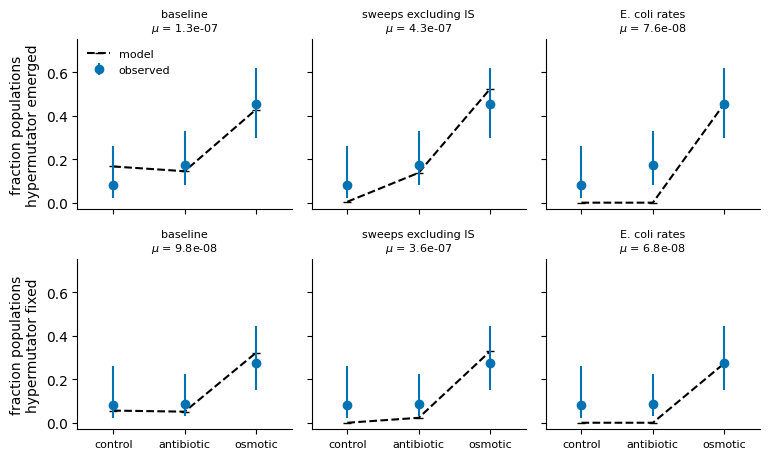

In [ ]:
def plot_takeover_by_stress(
    df_observed: pd.DataFrame, df_predicted: pd.DataFrame
) -> plt.Figure:
    fig, axs = plt.subplots(
        len(outcomes),
        len(scenarios),
        figsize=(2.6 * len(scenarios), 2.1 * len(outcomes) + 0.5),
        sharex=True,
        sharey=True,
        squeeze=False,
    )
    xs = np.arange(len(stresses))
    color = sns.color_palette("colorblind")[0]
    for row, outcome in zip(axs, outcomes):
        for ax, scenario in zip(row, scenarios):
            ax.errorbar(
                xs,
                df_observed[f"fraction {outcome}"],
                yerr=[
                    df_observed[f"fraction {outcome}"]
                    - df_observed[f"fraction {outcome} lo"],
                    df_observed[f"fraction {outcome} hi"]
                    - df_observed[f"fraction {outcome}"],
                ],
                color=color,
                marker="o",
                ls="none",
                label="observed",
                zorder=3,
            )
            predicted = (
                df_predicted[
                    (df_predicted["scenario"] == scenario)
                    & (df_predicted["outcome"] == outcome)
                ]
                .set_index("stress")
                .loc[stresses]
            )
            ys = predicted["fraction predicted"].where(
                np.isfinite(predicted["detection lag"]),
            )
            ax.plot(
                xs,
                ys,
                color="black",
                linestyle="--",
                marker="_",
                label="model",
            )
            mu = predicted["shared supply rate"].iloc[0]
            ax.set_title(
                f"{scenario}\n"
                + (rf"$\mu$ = {mu:.1e}" if np.isfinite(mu) else ""),
                fontsize=8,
            )
            ax.set_xticks(xs)
            ax.set_xticklabels(stresses, fontsize=8)
            ax.set_xlim(-0.5, len(stresses) - 0.5)
            ax.set_ylim(-0.03, 0.75)
        row[0].set_ylabel(f"fraction populations\nhypermutator {outcome}")
    axs[0, 0].legend(frameon=False, fontsize=8, loc="upper left")
    sns.despine(fig)
    fig.tight_layout()
    return fig

tp.tee(
    plot_takeover_by_stress,
    df_observed=df_observed,
    df_predicted=df_predicted,
    teeplot_subdir=teeplot_subdir,
)

## Timing of Emergence

Observed: transfer at which an IS10 insertion in *mutS* or *mutL* was first detected by PCR, among insertions still present at the end of the experiment.
Model: probability that a hypermutator lineage has reached 5% by a given transfer, under the baseline scenario with supply rate fitted to emergence at generation 1,000.
IS10 insertion is only one route to hypermutation, so the observed curve should fall at or below the model.

In [ ]:
_persisting = df_is10[
    df_is10["first detected transfer"].notna()
    & df_is10["final status"].str.contains("IS")
]
_num_assayed = df_is10.groupby("stress")["population"].nunique()
df_timing_observed = pd.concat(
    [
        pd.DataFrame(
            {
                "stress": stress,
                "transfer": np.sort(group["first detected transfer"]),
                "fraction populations": np.arange(1, len(group) + 1)
                / _num_assayed[stress],
            },
        )
        for stress, group in _persisting.groupby("stress")
    ],
)
_mu = df_fit.set_index(["scenario", "outcome"]).loc[
    ("baseline", "emerged"), "shared supply rate"
]
_inputs = df_inputs[
    (df_inputs["scenario"] == "baseline")
    & (df_inputs["outcome"] == "emerged")
].set_index("stress")
df_timing_model = pd.DataFrame(
    [
        {
            "stress": stress,
            "transfer": transfer,
            "fraction populations": calc_denovo_fixprob(
                _inputs.loc[stress, "population size"],
                _inputs.loc[stress, "available beneficial mutations"],
                s=_inputs.loc[stress, "selection strength"],
                mu=_mu,
                n_gen=int(
                    transfer * n_gen / 148
                    - _inputs.loc[stress, "detection lag"]
                ),
            )
            if transfer * n_gen / 148
            > _inputs.loc[stress, "detection lag"] + 1
            else 0.0,
        }
        for stress in ("antibiotic", "osmotic")
        for transfer in range(4, 149, 12)
    ],
)
df_timing_model

,stress,transfer,fraction populations
0,antibiotic,4,0.000000
1,antibiotic,16,0.000000
2,antibiotic,28,0.000000
3,antibiotic,40,0.000000
4,antibiotic,52,0.000029
...,...,...,...
21,osmotic,100,0.244355
22,osmotic,112,0.266862
23,osmotic,124,0.339616
24,osmotic,136,0.398326


teeplots/callens2023-hypermutator-emergence/viz=plot-emergence-timing+ext=.pdf
teeplots/callens2023-hypermutator-emergence/viz=plot-emergence-timing+ext=.png


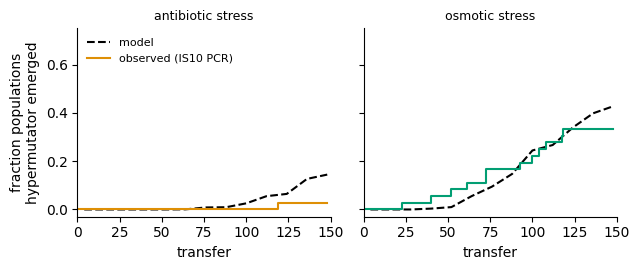

In [ ]:
def plot_emergence_timing(
    df_timing_observed: pd.DataFrame, df_timing_model: pd.DataFrame
) -> plt.Figure:
    fig, axs = plt.subplots(
        1, 2, figsize=(6.5, 2.8), sharex=True, sharey=True
    )
    palette = sns.color_palette("colorblind")
    for ax, stress, color in zip(
        axs, ("antibiotic", "osmotic"), palette[1:]
    ):
        model = df_timing_model[df_timing_model["stress"] == stress]
        ax.plot(
            model["transfer"],
            model["fraction populations"],
            color="black",
            linestyle="--",
            label="model",
        )
        observed = df_timing_observed[
            df_timing_observed["stress"] == stress
        ]
        ax.step(
            [0, *observed["transfer"], 148],
            [
                0,
                *observed["fraction populations"],
                observed["fraction populations"].max(),
            ],
            where="post",
            color=color,
            label="observed (IS10 PCR)",
        )
        ax.set_title(f"{stress} stress", fontsize=9)
        ax.set_xlabel("transfer")
        ax.set_xlim(0, 150)
        ax.set_ylim(-0.03, 0.75)
    axs[0].set_ylabel("fraction populations\nhypermutator emerged")
    axs[0].legend(frameon=False, fontsize=8, loc="upper left")
    sns.despine(fig)
    fig.tight_layout()
    return fig

tp.tee(
    plot_emergence_timing,
    df_timing_observed=df_timing_observed,
    df_timing_model=df_timing_model,
    teeplot_subdir=teeplot_subdir,
)